# Freight Rate Prediction

Chronological validation, model comparison, and final prediction generation.

September–October and July–August were both used during development; neither is an untouched final test. Spotter evaluates the unlabeled November–December data separately.


## 1. Setup

Install numpy, pandas, matplotlib, scikit-learn and catboost in the notebook environment before running. Run all cells in order. Original input files remain unchanged.


In [1]:
from pathlib import Path
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data"
OUT = ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
if not (DATA / "train_test.csv").is_file():
    raise FileNotFoundError(DATA / "train_test.csv")
print("Project root:", ROOT)


Project root: /home/minaibrahim/projects/spotter-freight-rate


## 2. Load and inspect raw data


In [2]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "data/train_test.csv")
df["date"] = pd.to_datetime(df["date"], errors="raise")
print(df.shape)
df.head()


(48000, 14)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [3]:
df.duplicated().sum()


np.int64(0)

In [4]:
df.isna().sum()


load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

## 3. Chronological split and data-quality inspection


In [5]:
train = df.loc[df["date"] < "2025-09-01"].copy()
holdout = df.loc[df["date"] >= "2025-09-01"].copy()

display(
    train[
        ["distance", "weight", "market_index", "quote_signal", "posted_rate"]
    ].describe(percentiles=[0.01, 0.5, 0.99]).T
)

display(train["equipment"].value_counts(dropna=False))

print("Non-positive distance:", (train["distance"] <= 0).sum())
print("Non-positive weight:", (train["weight"] <= 0).sum())
print("Non-positive rate:", (train["posted_rate"] <= 0).sum())

for name, part in [("train", train), ("holdout", holdout)]:
    print(name, len(part), part["date"].min(), part["date"].max())


,count,mean,std,min,1%,50%,99%,max
distance,38477.0,1136.008629,726.546072,70.00000,122.876000,954.80000,3022.592000,3439.80000
weight,38242.0,30991.677867,9384.832250,-47500.00000,9799.640000,31405.00000,47500.000000,47500.00000
market_index,38176.0,1.122381,0.160975,0.73250,0.811260,1.12000,1.410350,1.46778
quote_signal,38477.0,2.060900,0.288409,0.69228,1.315689,2.05361,2.876861,3.61035
posted_rate,38477.0,2369.409512,1476.502885,57.22000,326.999200,2026.04000,5968.611200,25533.00000


equipment
Dry Van    21842
Reefer      9652
Flatbed     6983
Name: count, dtype: int64

Non-positive distance: 0
Non-positive weight: 233
Non-positive rate: 0
train 38477 2025-01-01 00:00:00 2025-08-31 00:00:00
holdout 9523 2025-09-01 00:00:00 2025-10-31 00:00:00


## 4. Clean invalid weights and impute from training only


In [6]:
import numpy as np
import pandas as pd

df = pd.read_csv(ROOT / "data/train_test.csv")
df["date"] = pd.to_datetime(df["date"], errors="raise")

train = df.loc[df["date"] < "2025-09-01"].copy()
holdout = df.loc[df["date"] >= "2025-09-01"].copy()

for part in (train, holdout):
    part["weight_invalid"] = (part["weight"] <= 0).astype("int8")
    part.loc[part["weight"] <= 0, "weight"] = np.nan

    part["weight_missing"] = part["weight"].isna().astype("int8")
    part["market_index_missing"] = (
        part["market_index"].isna().astype("int8")
    )

medians = train[["weight", "market_index"]].median()

for part in (train, holdout):
    part[["weight", "market_index"]] = (
        part[["weight", "market_index"]].fillna(medians)
    )

print("Training medians:\n", medians)
print("\nRemaining missing values:")
print(train[["weight", "market_index"]].isna().sum())

display(
    train.nlargest(10, "posted_rate")[
        ["pickup", "delivery", "distance", "equipment",
         "weight", "date", "quote_signal", "posted_rate"]
    ]
)


Training medians:
 weight          31467.00
market_index        1.12
dtype: float64

Remaining missing values:
weight          0
market_index    0
dtype: int64


,pickup,delivery,distance,equipment,weight,date,quote_signal,posted_rate
12184,Bakersfield,Hartford,2829.8,Dry Van,33153.0,2025-03-19,1.83188,25533.00
37764,Phoenix,Syracuse,2810.9,Dry Van,33674.0,2025-08-27,2.16284,24294.98
1466,Los Angeles,Syracuse,2786.0,Reefer,30322.0,2025-01-10,1.85370,24140.21
17371,Reno,Philadelphia,2777.6,Reefer,33158.0,2025-04-20,2.15601,23662.71
26235,Charleston,Phoenix,2552.5,Dry Van,25665.0,2025-06-15,1.81289,23580.42
28219,Tucson,Raleigh,2423.3,Dry Van,30972.0,2025-06-27,1.97112,22755.66
3353,Phoenix,Charleston,2527.9,Reefer,36840.0,2025-01-22,2.07342,22534.65
31259,Oklahoma City,Baltimore,1747.7,Reefer,28876.0,2025-07-16,1.80406,19042.39
34583,Atlanta,Fresno,2242.0,Dry Van,32005.0,2025-08-06,1.98678,18972.15
20245,Atlanta,Los Angeles,2153.5,Reefer,31758.0,2025-05-08,1.96054,17772.53


## 5. Explore rates and potential outliers


In [7]:
diagnostics = train.assign(
    rate_per_mile=train["posted_rate"] / train["distance"]
)

display(
    diagnostics[
        ["rate_per_mile", "quote_signal"]
    ].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T
)

display(
    diagnostics.nlargest(15, "rate_per_mile")[
        ["distance", "equipment", "quote_signal",
         "posted_rate", "rate_per_mile"]
    ]
)

print(
    "Correlation:",
    diagnostics["rate_per_mile"].corr(diagnostics["quote_signal"])
)


,count,mean,std,min,1%,50%,95%,99%,max
rate_per_mile,38477.0,2.210523,0.580404,0.333709,1.668820,2.141151,2.727984,3.160996,14.125294
quote_signal,38477.0,2.060900,0.288409,0.692280,1.315689,2.053610,2.544558,2.876861,3.610350


,distance,equipment,quote_signal,posted_rate,rate_per_mile
22254,314.7,Reefer,1.24215,4445.23,14.125294
36609,98.4,Reefer,2.58457,1386.42,14.089634
870,305.6,Reefer,2.64181,4069.24,13.315576
17070,201.5,Flatbed,1.44259,2609.34,12.949578
27969,589.9,Reefer,2.58804,7597.52,12.879335
23369,412.4,Flatbed,1.40576,5308.96,12.873327
28012,604.3,Reefer,2.76111,7773.37,12.863429
1415,198.2,Reefer,2.66449,2509.96,12.663774
21968,254.5,Dry Van,1.52868,3220.66,12.654853
7841,353.0,Reefer,2.53068,4368.67,12.375836


Correlation: 0.062105817635228044


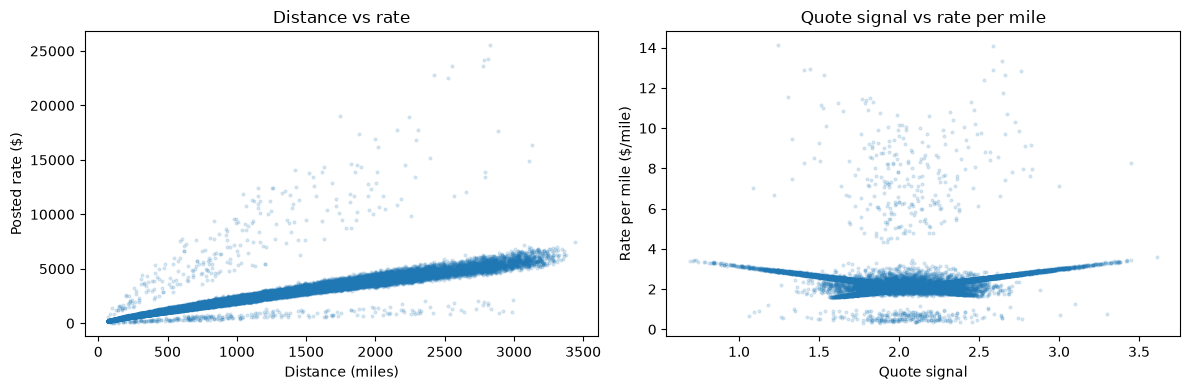

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    train["distance"], train["posted_rate"],
    s=4, alpha=0.15
)
axes[0].set(
    xlabel="Distance (miles)",
    ylabel="Posted rate ($)",
    title="Distance vs rate"
)

axes[1].scatter(
    diagnostics["quote_signal"],
    diagnostics["rate_per_mile"],
    s=4, alpha=0.15
)
axes[1].set(
    xlabel="Quote signal",
    ylabel="Rate per mile ($/mile)",
    title="Quote signal vs rate per mile"
)

plt.tight_layout()
plt.show()


## 6. Distance-based baseline


In [9]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

y_train = train["posted_rate"]
y_holdout = holdout["posted_rate"]

def evaluate(name, predictions):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_holdout, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_holdout, predictions)),
        "R2": r2_score(y_holdout, predictions),
    }

median_rate_per_mile = (
    train["posted_rate"] / train["distance"]
).median()

baseline_predictions = (
    holdout["distance"].to_numpy() * median_rate_per_mile
)

results = [
    evaluate("Median rate per mile × distance", baseline_predictions)
]

print(f"Training median $/mile: {median_rate_per_mile:.4f}")
display(pd.DataFrame(results))


Training median $/mile: 2.1412


,model,MAE,RMSE,R2
0,Median rate per mile × distance,256.952939,684.247911,0.798957


## 7. Ridge regression


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge

def make_features(frame):
    features = frame[
        ["pickup", "delivery", "equipment", "distance", "weight"]
    ].copy()

    dates = pd.to_datetime(frame["date"])
    features["day_of_week"] = dates.dt.dayofweek.astype(str)
    features["month"] = dates.dt.month.astype(str)

    return features

X_train = make_features(train)
X_holdout = make_features(holdout)

numeric_cols = ["distance", "weight"]
categorical_cols = [
    "pickup", "delivery", "equipment", "day_of_week", "month"
]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_cols),
])

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0, solver="lsqr")),
])

ridge_model.fit(X_train, y_train)

ridge_predictions = np.maximum(
    ridge_model.predict(X_holdout), 0.01
)

ridge_result = evaluate("Ridge — core features", ridge_predictions)

results = [r for r in results if r["model"] != ridge_result["model"]]
results.append(ridge_result)

display(pd.DataFrame(results))


,model,MAE,RMSE,R2
0,Median rate per mile × distance,256.952939,684.247911,0.798957
1,Ridge — core features,141.463918,637.445452,0.825519


## 8. Random Forest


In [11]:
from sklearn.ensemble import RandomForestRegressor

forest_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_cols),
])

forest_model = Pipeline([
    ("preprocessor", forest_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=18,
        min_samples_leaf=10,
        max_features=0.8,
        random_state=42,
        n_jobs=-1,
    )),
])

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_holdout)

forest_result = evaluate(
    "Random Forest — core features",
    forest_predictions,
)

results = [
    r for r in results
    if r["model"] != forest_result["model"]
]
results.append(forest_result)

display(pd.DataFrame(results))


,model,MAE,RMSE,R2
0,Median rate per mile × distance,256.952939,684.247911,0.798957
1,Ridge — core features,141.463918,637.445452,0.825519
2,Random Forest — core features,124.963642,633.202858,0.827834


## 9. Neural-network comparison


In [12]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

mlp_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
    ), categorical_cols),
])

mlp_pipeline = Pipeline([
    ("preprocessor", mlp_preprocessor),
    ("model", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        alpha=0.01,
        learning_rate_init=0.001,
        batch_size=256,
        max_iter=150,
        early_stopping=False,
        random_state=42,
    )),
])

mlp_model = TransformedTargetRegressor(
    regressor=mlp_pipeline,
    transformer=StandardScaler(),
)

mlp_model.fit(X_train, y_train)

mlp_predictions = np.maximum(
    mlp_model.predict(X_holdout), 0.01
)

mlp_result = evaluate("MLP — core features", mlp_predictions)

results = [r for r in results if r["model"] != mlp_result["model"]]
results.append(mlp_result)

display(pd.DataFrame(results))

network = mlp_model.regressor_.named_steps["model"]
print("Training iterations:", network.n_iter_)


,model,MAE,RMSE,R2
0,Median rate per mile × distance,256.952939,684.247911,0.798957
1,Ridge — core features,141.463918,637.445452,0.825519
2,Random Forest — core features,124.963642,633.202858,0.827834
3,MLP — core features,142.776394,667.028454,0.808949


Training iterations: 88


## 10. Additional market features


In [13]:
from sklearn.base import clone

feature_experiments = [
    ("RF + market_index", ["market_index"]),
    ("RF + market_index + quote_signal",
     ["market_index", "quote_signal"]),
]

feature_models = {}

for name, extra_cols in feature_experiments:
    X_train_extra = X_train.copy()
    X_holdout_extra = X_holdout.copy()

    for col in extra_cols:
        X_train_extra[col] = train[col]
        X_holdout_extra[col] = holdout[col]

    preprocessing = ColumnTransformer([
        ("numeric", "passthrough", numeric_cols + extra_cols),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),
    ])

    model = Pipeline([
        ("preprocessor", preprocessing),
        ("model", clone(forest_model.named_steps["model"])),
    ])

    model.fit(X_train_extra, y_train)
    predictions = model.predict(X_holdout_extra)

    feature_models[name] = model

    result = evaluate(name, predictions)
    results = [r for r in results if r["model"] != name]
    results.append(result)

display(pd.DataFrame(results))


,model,MAE,RMSE,R2
0,Median rate per mile × distance,256.952939,684.247911,0.798957
1,Ridge — core features,141.463918,637.445452,0.825519
2,Random Forest — core features,124.963642,633.202858,0.827834
3,MLP — core features,142.776394,667.028454,0.808949
4,RF + market_index,146.834388,643.070866,0.822426
5,RF + market_index + quote_signal,119.195166,635.449763,0.826610


Market-feature comparisons are exploratory. The December scenario omits these columns, and quote_signal availability and provenance are undocumented. Missingness flags created above were not included in the model features.


## 11. CatBoost comparison


In [14]:
from catboost import CatBoostRegressor

cb_train = X_train.copy()
cb_holdout = X_holdout.copy()

for col in categorical_cols:
    cb_train[col] = cb_train[col].astype(str)
    cb_holdout[col] = cb_holdout[col].astype(str)

catboost_model = CatBoostRegressor(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    thread_count=4,
    verbose=100,
    allow_writing_files=False,
)

catboost_model.fit(
    cb_train,
    y_train,
    cat_features=categorical_cols,
)

cb_predictions = np.maximum(
    catboost_model.predict(cb_holdout), 0.01
)

cb_result = evaluate("CatBoost — core features", cb_predictions)
results = [r for r in results if r["model"] != cb_result["model"]]
results.append(cb_result)

display(pd.DataFrame(results))


0:	learn: 1418.3002451	total: 54.7ms	remaining: 32.8s
100:	learn: 584.4529608	total: 666ms	remaining: 3.29s
200:	learn: 580.7429528	total: 1.22s	remaining: 2.43s
300:	learn: 578.0827337	total: 1.74s	remaining: 1.73s
400:	learn: 575.7135798	total: 2.25s	remaining: 1.12s
500:	learn: 573.7279796	total: 2.74s	remaining: 542ms
599:	learn: 570.9406208	total: 3.3s	remaining: 0us


,model,MAE,RMSE,R2
0,Median rate per mile × distance,256.952939,684.247911,0.798957
1,Ridge — core features,141.463918,637.445452,0.825519
2,Random Forest — core features,124.963642,633.202858,0.827834
3,MLP — core features,142.776394,667.028454,0.808949
4,RF + market_index,146.834388,643.070866,0.822426
5,RF + market_index + quote_signal,119.195166,635.449763,0.826610
6,CatBoost — core features,182.191186,652.900567,0.816956


## 12. Geographic features


In [15]:
from sklearn.base import clone

geo_cols = [
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon",
]

X_train_geo = X_train.copy()
X_holdout_geo = X_holdout.copy()

for col in geo_cols:
    X_train_geo[col] = train[col]
    X_holdout_geo[col] = holdout[col]

geo_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_cols + geo_cols),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_cols),
])

forest_geo_model = Pipeline([
    ("preprocessor", geo_preprocessor),
    ("model", clone(forest_model.named_steps["model"])),
])

forest_geo_model.fit(X_train_geo, y_train)

geo_predictions = forest_geo_model.predict(X_holdout_geo)
geo_result = evaluate("Random Forest — core + coordinates", geo_predictions)

results = [r for r in results if r["model"] != geo_result["model"]]
results.append(geo_result)

display(pd.DataFrame(results))


,model,MAE,RMSE,R2
0,Median rate per mile × distance,256.952939,684.247911,0.798957
1,Ridge — core features,141.463918,637.445452,0.825519
2,Random Forest — core features,124.963642,633.202858,0.827834
3,MLP — core features,142.776394,667.028454,0.808949
4,RF + market_index,146.834388,643.070866,0.822426
5,RF + market_index + quote_signal,119.195166,635.449763,0.826610
6,CatBoost — core features,182.191186,652.900567,0.816956
7,Random Forest — core + coordinates,117.293534,632.237483,0.828359


## 13. Additional chronological validation


In [16]:
from sklearn.base import clone

raw = pd.read_csv(ROOT / "data/train_test.csv")
raw["date"] = pd.to_datetime(raw["date"], errors="raise")

early_train = raw.loc[raw["date"] < "2025-07-01"].copy()

early_valid = raw.loc[
    (raw["date"] >= "2025-07-01") &
    (raw["date"] < "2025-09-01")
].copy()

for part in (early_train, early_valid):
    part.loc[part["weight"] <= 0, "weight"] = np.nan

early_weight_median = early_train["weight"].median()

for part in (early_train, early_valid):
    part["weight"] = part["weight"].fillna(early_weight_median)

X_early_train = make_features(early_train)
X_early_valid = make_features(early_valid)

y_early_train = early_train["posted_rate"]
y_early_valid = early_valid["posted_rate"]

early_results = []

for name, original_model in [
    ("Ridge — core", ridge_model),
    ("Random Forest — core", forest_model),
]:
    model = clone(original_model)
    model.fit(X_early_train, y_early_train)

    predictions = np.maximum(
        model.predict(X_early_valid), 0.01
    )

    early_results.append({
        "model": name,
        "MAE": mean_absolute_error(y_early_valid, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_early_valid, predictions)
        ),
        "R2": r2_score(y_early_valid, predictions),
    })

print("Train:", len(early_train), "| Validation:", len(early_valid))
display(pd.DataFrame(early_results))


Train: 28806 | Validation: 9671


,model,MAE,RMSE,R2
0,Ridge — core,141.836578,628.402608,0.822276
1,Random Forest — core,128.963855,628.610039,0.822159


In [17]:
X_early_train_geo = X_early_train.copy()
X_early_valid_geo = X_early_valid.copy()

for col in geo_cols:
    X_early_train_geo[col] = early_train[col]
    X_early_valid_geo[col] = early_valid[col]

early_geo_model = clone(forest_geo_model)
early_geo_model.fit(X_early_train_geo, y_early_train)

early_geo_predictions = early_geo_model.predict(X_early_valid_geo)

early_geo_result = {
    "model": "Random Forest — core + coordinates",
    "MAE": mean_absolute_error(y_early_valid, early_geo_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_early_valid, early_geo_predictions)
    ),
    "R2": r2_score(y_early_valid, early_geo_predictions),
}

early_results = [
    r for r in early_results
    if r["model"] != early_geo_result["model"]
]
early_results.append(early_geo_result)

display(pd.DataFrame(early_results))


,model,MAE,RMSE,R2
0,Ridge — core,141.836578,628.402608,0.822276
1,Random Forest — core,128.963855,628.610039,0.822159
2,Random Forest — core + coordinates,121.853805,628.109109,0.822442


## 14. Selected-model error analysis


In [18]:
errors = holdout[
    ["pickup", "delivery", "distance", "equipment", "date", "posted_rate"]
].copy()

errors["prediction"] = geo_predictions
errors["residual"] = errors["posted_rate"] - errors["prediction"]
errors["absolute_error"] = errors["residual"].abs()

display(errors.nlargest(10, "absolute_error"))

display(
    errors["absolute_error"]
    .quantile([0.50, 0.90, 0.95, 0.99])
    .rename("Absolute error ($)")
)

display(
    errors.groupby(errors["date"].dt.to_period("M")).agg(
        loads=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean"),
    )
)


,pickup,delivery,distance,equipment,date,posted_rate,prediction,residual,absolute_error
40096,Baltimore,Oklahoma City,1760.3,Reefer,2025-09-11,20132.37,3952.474702,16179.895298,16179.895298
40171,Montgomery,Fresno,2283.4,Dry Van,2025-09-11,20361.89,4655.236071,15706.653929,15706.653929
43539,Milwaukee,Bakersfield,1893.0,Dry Van,2025-10-03,17514.11,3692.390999,13821.719001,13821.719001
46213,Columbia,Tucson,2023.4,Flatbed,2025-10-20,17893.17,4195.379353,13697.790647,13697.790647
47298,Boston,Bakersfield,2979.1,Reefer,2025-10-27,19110.30,5996.226386,13114.073614,13114.073614
40322,Montgomery,El Paso,1639.9,Dry Van,2025-09-12,14949.25,3260.129925,11689.120075,11689.120075
46516,Toledo,Albuquerque,1684.3,Reefer,2025-10-22,14784.38,3736.835749,11047.544251,11047.544251
42881,San Antonio,Detroit,1460.5,Dry Van,2025-09-29,13503.63,3214.969407,10288.660593,10288.660593
44267,Albany,Albuquerque,2492.6,Dry Van,2025-10-08,14425.42,4333.274011,10092.145989,10092.145989
46366,Bakersfield,Columbia,2251.9,Dry Van,2025-10-21,14403.14,4335.360076,10067.779924,10067.779924


0.50      39.292491
0.90     154.300512
0.95     227.533985
0.99    1529.073929
Name: Absolute error ($), dtype: float64

,loads,MAE,mean_residual
date,,,
2025-09,4670,114.717971,20.964705
2025-10,4853,119.771976,29.801650


## 15. December input compatibility


In [19]:
december = pd.read_csv(ROOT / "data/december_chart_inputs.csv")
december_features = make_features(december)

display(december_features.head())
print(december_features.isna().sum())

for col in categorical_cols:
    unseen = set(december_features[col]) - set(X_train[col])
    print(f"{col} — unseen values:", unseen)


,pickup,delivery,equipment,distance,weight,day_of_week,month
0,Lexington,Fort Wayne,Dry Van,360,32000,0,12
1,Lexington,Fort Wayne,Dry Van,360,32000,1,12
2,Lexington,Fort Wayne,Dry Van,360,32000,2,12
3,Lexington,Fort Wayne,Dry Van,360,32000,3,12
4,Lexington,Fort Wayne,Dry Van,360,32000,4,12


pickup         0
delivery       0
equipment      0
distance       0
weight         0
day_of_week    0
month          0
dtype: int64
pickup — unseen values: set()
delivery — unseen values: set()
equipment — unseen values: set()
day_of_week — unseen values: set()
month — unseen values: {'12'}


In [20]:
city_coords = pd.concat([
    train[["pickup", "pickup_lat", "pickup_lon"]].rename(
        columns={
            "pickup": "city",
            "pickup_lat": "lat",
            "pickup_lon": "lon",
        }
    ),
    train[["delivery", "delivery_lat", "delivery_lon"]].rename(
        columns={
            "delivery": "city",
            "delivery_lat": "lat",
            "delivery_lon": "lon",
        }
    ),
], ignore_index=True).drop_duplicates()

conflicts = city_coords.groupby("city").size()
print("Cities with conflicting coordinates:")
display(conflicts[conflicts > 1])

display(
    city_coords[
        city_coords["city"].isin(["Lexington", "Fort Wayne"])
    ]
)


Cities with conflicting coordinates:


Series([], dtype: int64)

,city,lat,lon
28,Lexington,36.99152,-84.99876
55,Fort Wayne,41.31561,-85.36206


In [21]:
assert not (conflicts > 1).any(), "Conflicting city coordinates"
assert {"Lexington", "Fort Wayne"}.issubset(set(city_coords["city"]))


## 16. Refit selected model and generate final predictions


In [22]:
def make_geo_features(frame):
    features = make_features(frame)

    for col in geo_cols:
        features[col] = frame[col]

    return features


full_geo = pd.read_csv(ROOT / "data/train_test.csv")
loads_geo = pd.read_csv(ROOT / "data/validation.csv")
december_geo = pd.read_csv(ROOT / "data/december_chart_inputs.csv")

full_geo.loc[full_geo["weight"] <= 0, "weight"] = np.nan
geo_weight_median = full_geo["weight"].median()

for part in (full_geo, loads_geo, december_geo):
    part.loc[part["weight"] <= 0, "weight"] = np.nan
    part["weight"] = part["weight"].fillna(geo_weight_median)

lookup = city_coords.set_index("city")

for endpoint in ["pickup", "delivery"]:
    december_geo[f"{endpoint}_lat"] = (
        december_geo[endpoint].map(lookup["lat"])
    )
    december_geo[f"{endpoint}_lon"] = (
        december_geo[endpoint].map(lookup["lon"])
    )

assert december_geo[geo_cols].notna().all().all()

final_geo_model = clone(forest_geo_model)
final_geo_model.fit(
    make_geo_features(full_geo),
    full_geo["posted_rate"],
)

submission = pd.read_csv(
    ROOT / "data/validation_predictions_template.csv"
)

assert loads_geo["load_id"].is_unique
assert submission["load_id"].is_unique
assert set(submission["load_id"]) == set(loads_geo["load_id"])

pred_by_id = pd.Series(
    final_geo_model.predict(make_geo_features(loads_geo)),
    index=loads_geo["load_id"],
)
submission["predicted_rate"] = submission["load_id"].map(pred_by_id)

december_final = pd.read_csv(
    ROOT / "data/december_chart_inputs.csv"
)
december_final["predicted_rate"] = final_geo_model.predict(
    make_geo_features(december_geo)
)

assert len(submission) == 12_000
assert len(december_final) == 31

for values in [
    submission["predicted_rate"],
    december_final["predicted_rate"],
]:
    assert np.isfinite(values).all()
    assert (values > 0).all()

submission.to_csv(OUT / "validation_predictions.csv", index=False)
december_final.to_csv(OUT / "december_predictions.csv", index=False)

print("Updated outputs using Random Forest + coordinates.")
display(december_final[["date", "predicted_rate"]].head())


Updated outputs using Random Forest + coordinates.


,date,predicted_rate
0,2025-12-01,848.313883
1,2025-12-02,848.563285
2,2025-12-03,848.733088
3,2025-12-04,848.694277
4,2025-12-05,847.966917


## 17. Validate submission files and generate the required chart


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /home/minaibrahim/projects/spotter-freight-rate/outputs/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



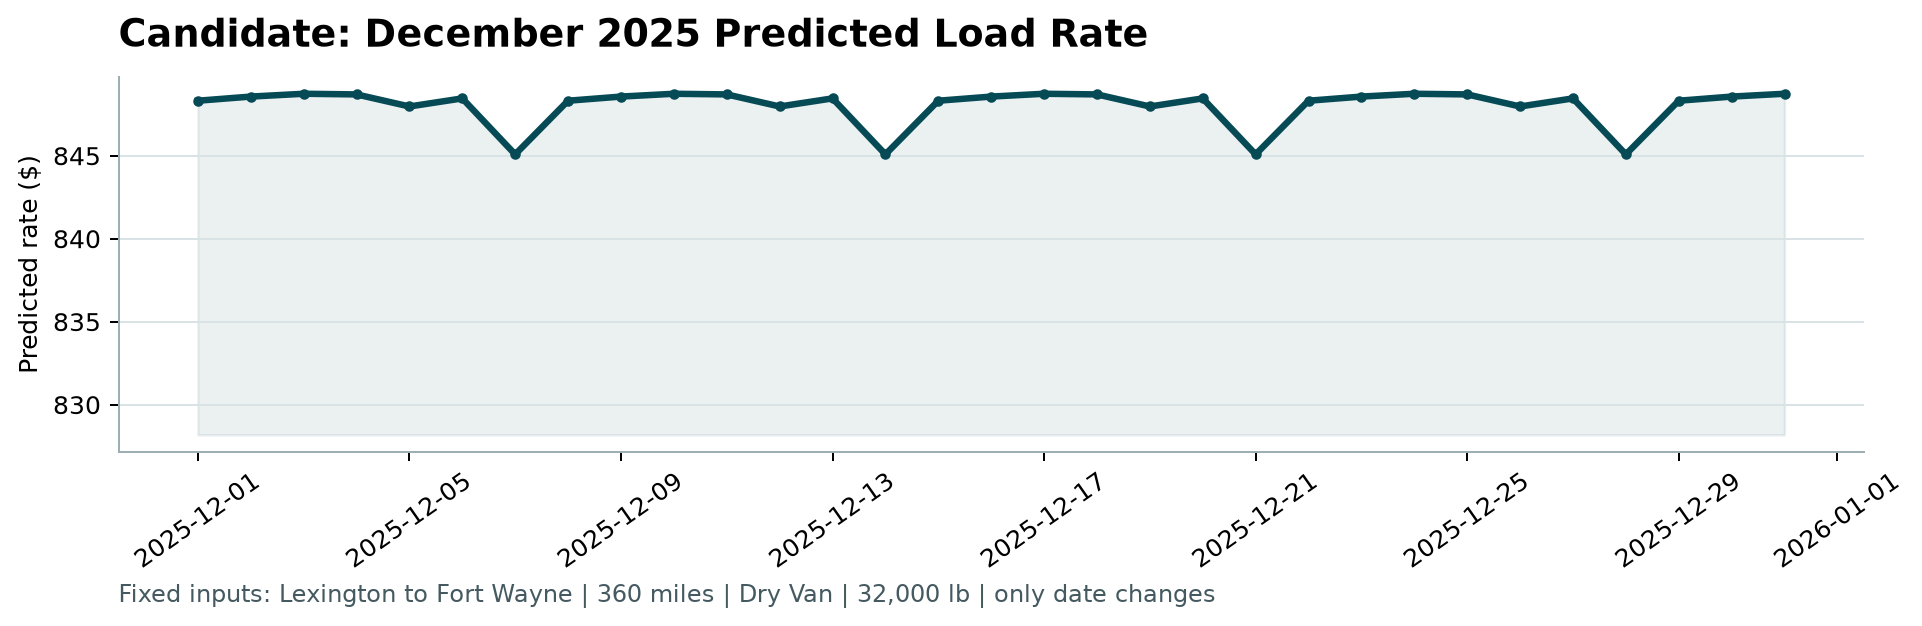

Scorer passed and comparison tables saved.


In [23]:
import subprocess
import sys
from IPython.display import Image, display

checked = subprocess.run(
    [
        sys.executable,
        str(ROOT / "score.py"),
        "--predictions",
        str(OUT / "validation_predictions.csv"),
        "--december-predictions",
        str(OUT / "december_predictions.csv"),
        "--output-dir",
        str(OUT / "scorer_results"),
    ],
    capture_output=True,
    text=True,
)

print(checked.stdout)
if checked.stderr:
    print(checked.stderr)

checked.check_returncode()

display(Image(
    filename=str(OUT / "scorer_results/candidate_december.png")
))

pd.DataFrame(results).to_csv(
    OUT / "model_comparison_sep_oct.csv", index=False
)
pd.DataFrame(early_results).to_csv(
    OUT / "model_comparison_jul_aug.csv", index=False
)

print("Scorer passed and comparison tables saved.")


## Interpretation and limitations

- Random Forest with coordinates was selected for consistent MAE improvements across both development windows; RMSE gains were small.
- Extreme target values were retained in training and evaluation; they were not proven to be errors.
- Invalid non-positive weights were treated as missing, with medians learned only from the relevant training period.
- December is an unseen month category. The chart reflects learned weekday effects, not validated December or holiday seasonality.
- The chart shading is decorative, not a prediction interval.
- score.py checks output structure and creates a chart; it does not measure hidden-set prediction accuracy.
- City coordinates for the December scenario come from the checked labeled-data lookup, not external geocoding.
